In [ ]:
from utils.library import *
from utils.download import *
from utils.metrics import split_temporal
from utils.stock_config import *
from models.arima import *
from models.xgboost import run_xgbooster
from utils.plots import plot_forecast
from models.lstm import run_lstm

## Buscando os dados

In [2]:
itub_csv = 'data/itub.csv'
if not os.path.exists(itub_csv):
    itub4_dataset = load_stock(STOCKS["itub"], "itub", force=True)
    itub4_dataset.head(10)

itub4_dataset = pd.read_csv(itub_csv)

In [3]:
itub4_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 3974 entries, 0 to 3973
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          3974 non-null   str    
 1   itub_close    3974 non-null   float64
 2   itub_high     3974 non-null   float64
 3   itub_low      3974 non-null   float64
 4   itub_open     3974 non-null   float64
 5   itub_volume   3974 non-null   int64  
 6   ibovespa      3974 non-null   float64
 7   vix           3974 non-null   float64
 8   selic_daily   3974 non-null   float64
 9   selic_goal    3974 non-null   float64
 10  ipca          3974 non-null   float64
 11  fx_usd        3974 non-null   float64
 12  gdp           3974 non-null   float64
 13  unemployment  3439 non-null   float64
dtypes: float64(12), int64(1), str(1)
memory usage: 434.8 KB


## ARIMA

In [4]:
train_itub, test_itub = split_temporal(itub4_dataset)
res_itub = run_arima(train_itub, test_itub, "itub")

--- Identificando ordem do ARIMA para ITUB ---
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=389.585, Time=1.32 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=415.847, Time=0.13 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=407.743, Time=0.08 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=407.854, Time=0.11 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=414.596, Time=0.16 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=411.606, Time=0.29 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=411.608, Time=0.89 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=402.038, Time=1.75 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=389.719, Time=2.13 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=409.611, Time=0.20 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=405.550, Time=2.43 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=410.099, Time=0.90 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=391.548, Time=7.54 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=386.837, Time=3.59 sec


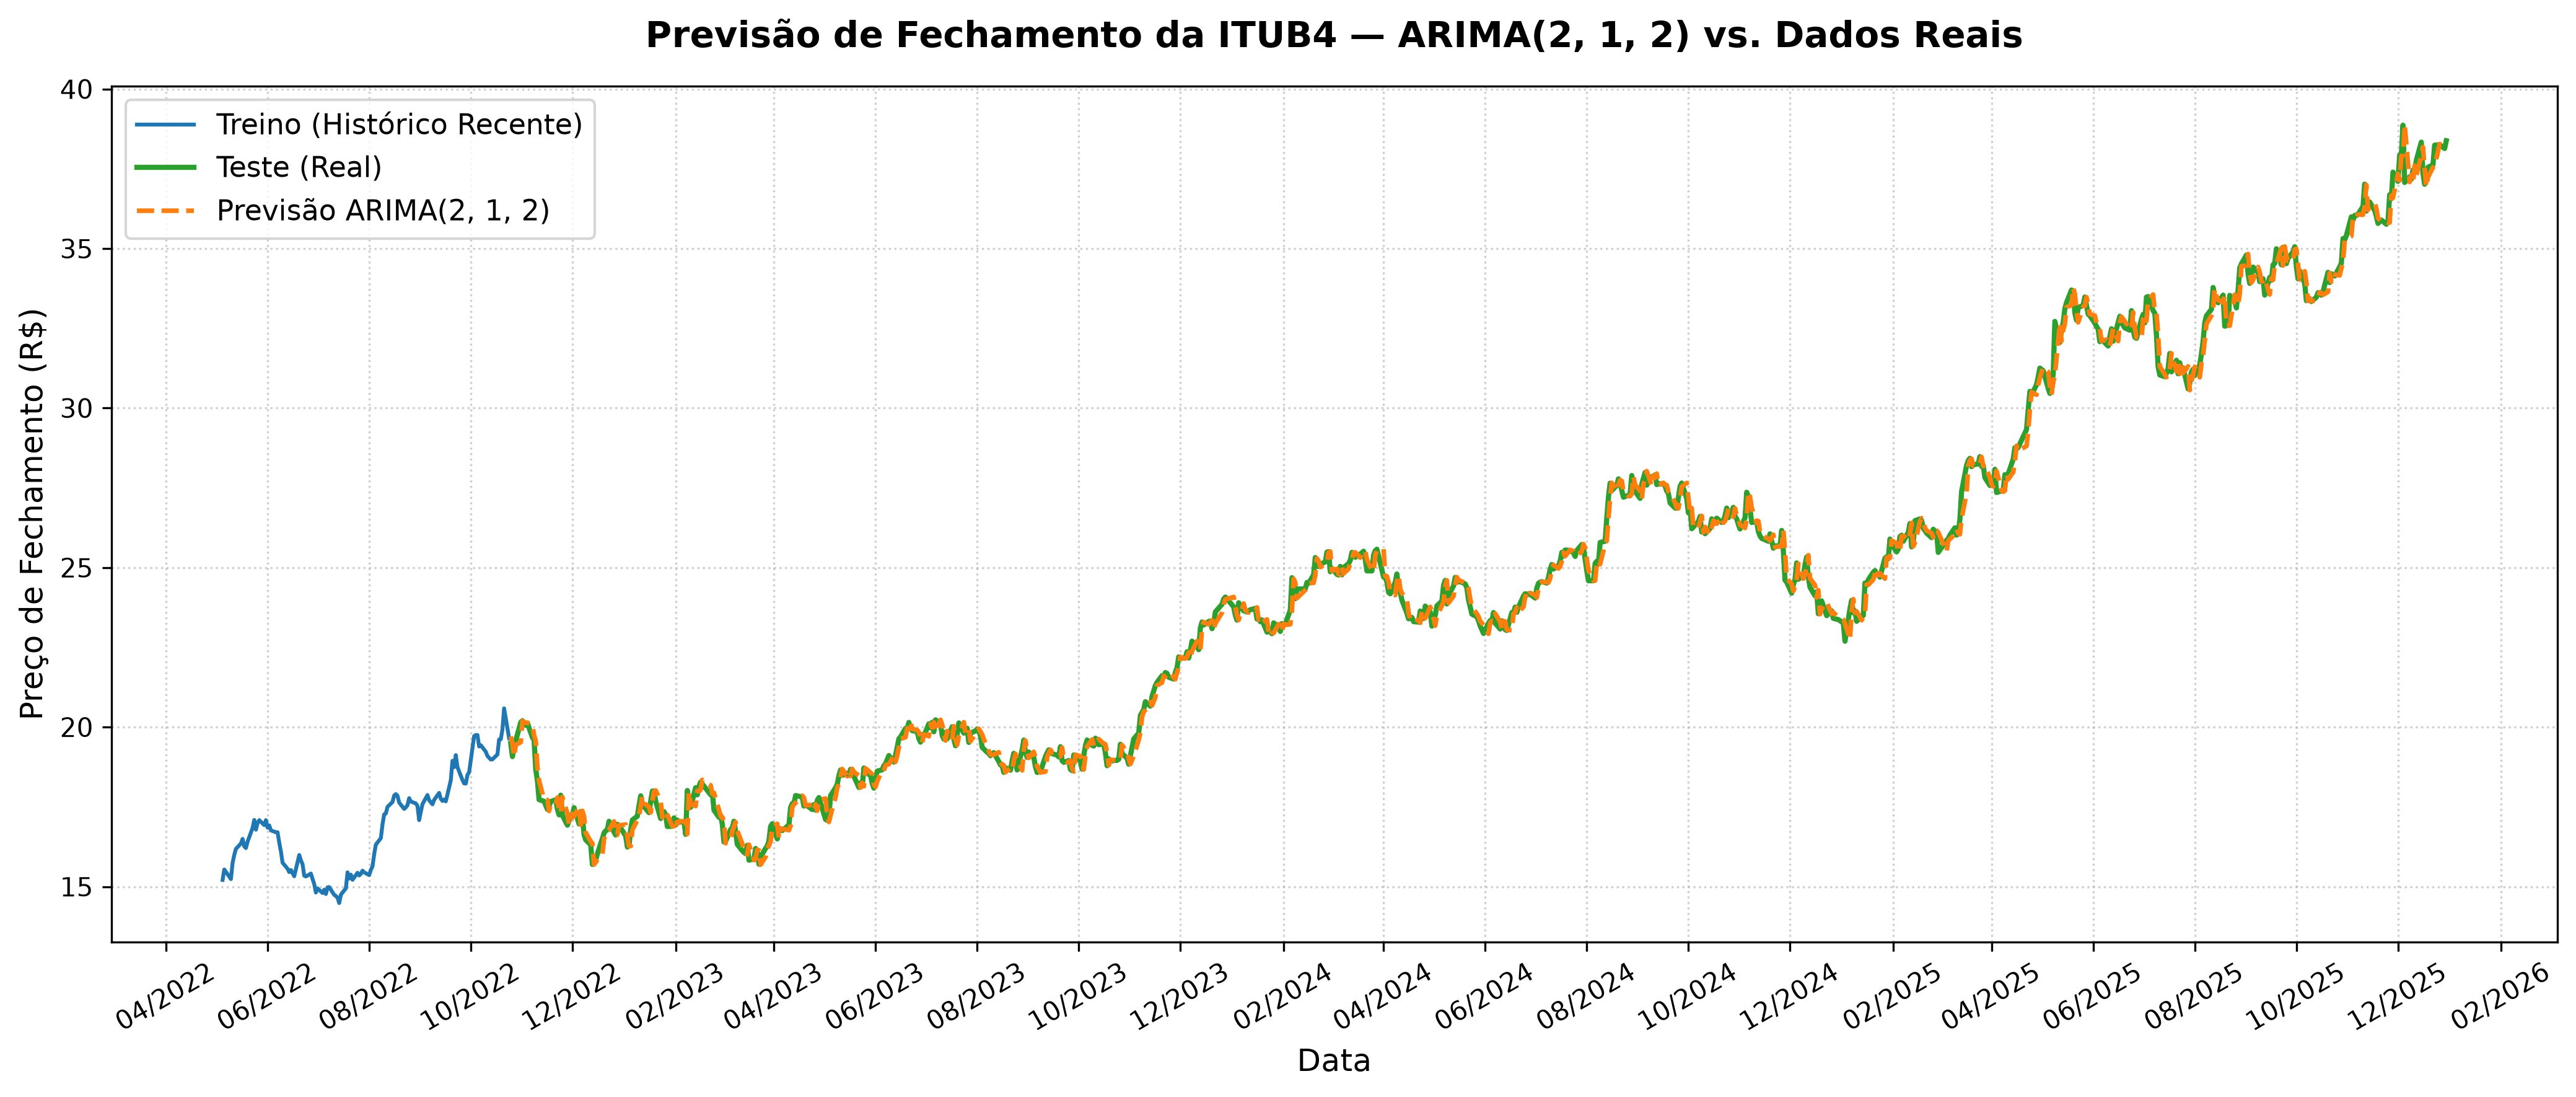

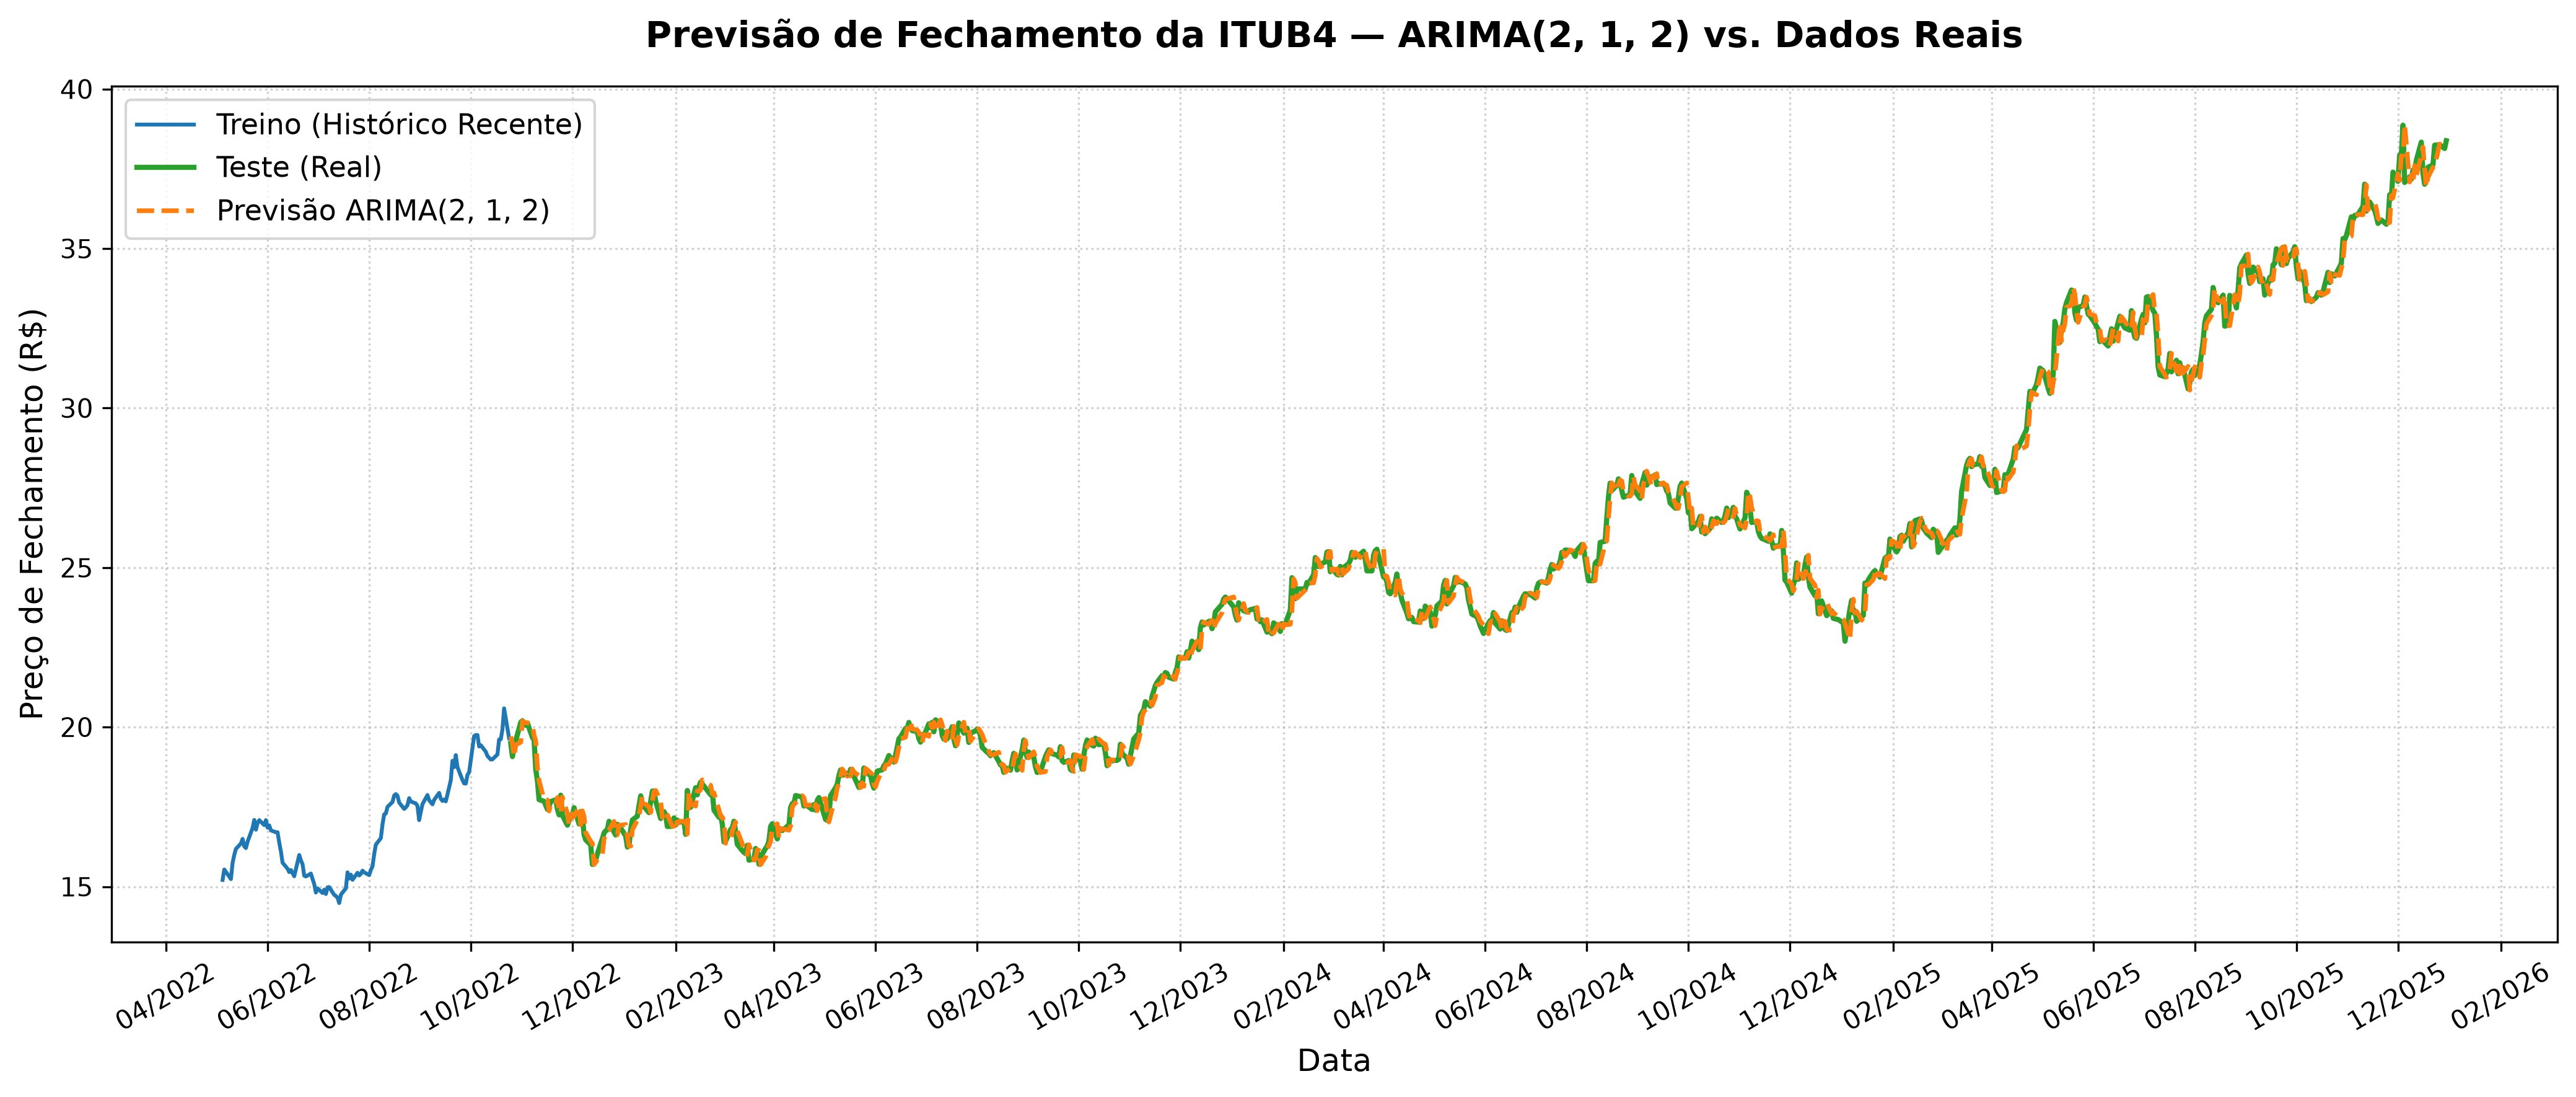

In [5]:
plot_forecast(
    train_itub, test_itub,
    predictions=res_itub["predictions"],
    stock_name="itub",
    model_name=f"ARIMA{res_itub['order']}",
    ticker_label="ITUB4",
)

## XGBooster

--- XGBoost ITUB: 37 features, 2641 treino / 795 teste ---
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Melhores hiperparâmetros: {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 500, 'subsample': 1.0}
Melhor RMSE médio (validação): 1.5995
XGBoost itub           RMSE: 6.1306 | MAE: 4.0901 | MAPE: 13.50% | Acurácia direcional: 50.31%
Naive itub             RMSE: 0.3294 | MAE: 0.2464 | MAPE: 1.02% | Acurácia direcional: n/a
p-valor (teste binomial, acurácia direcional): 0.8872


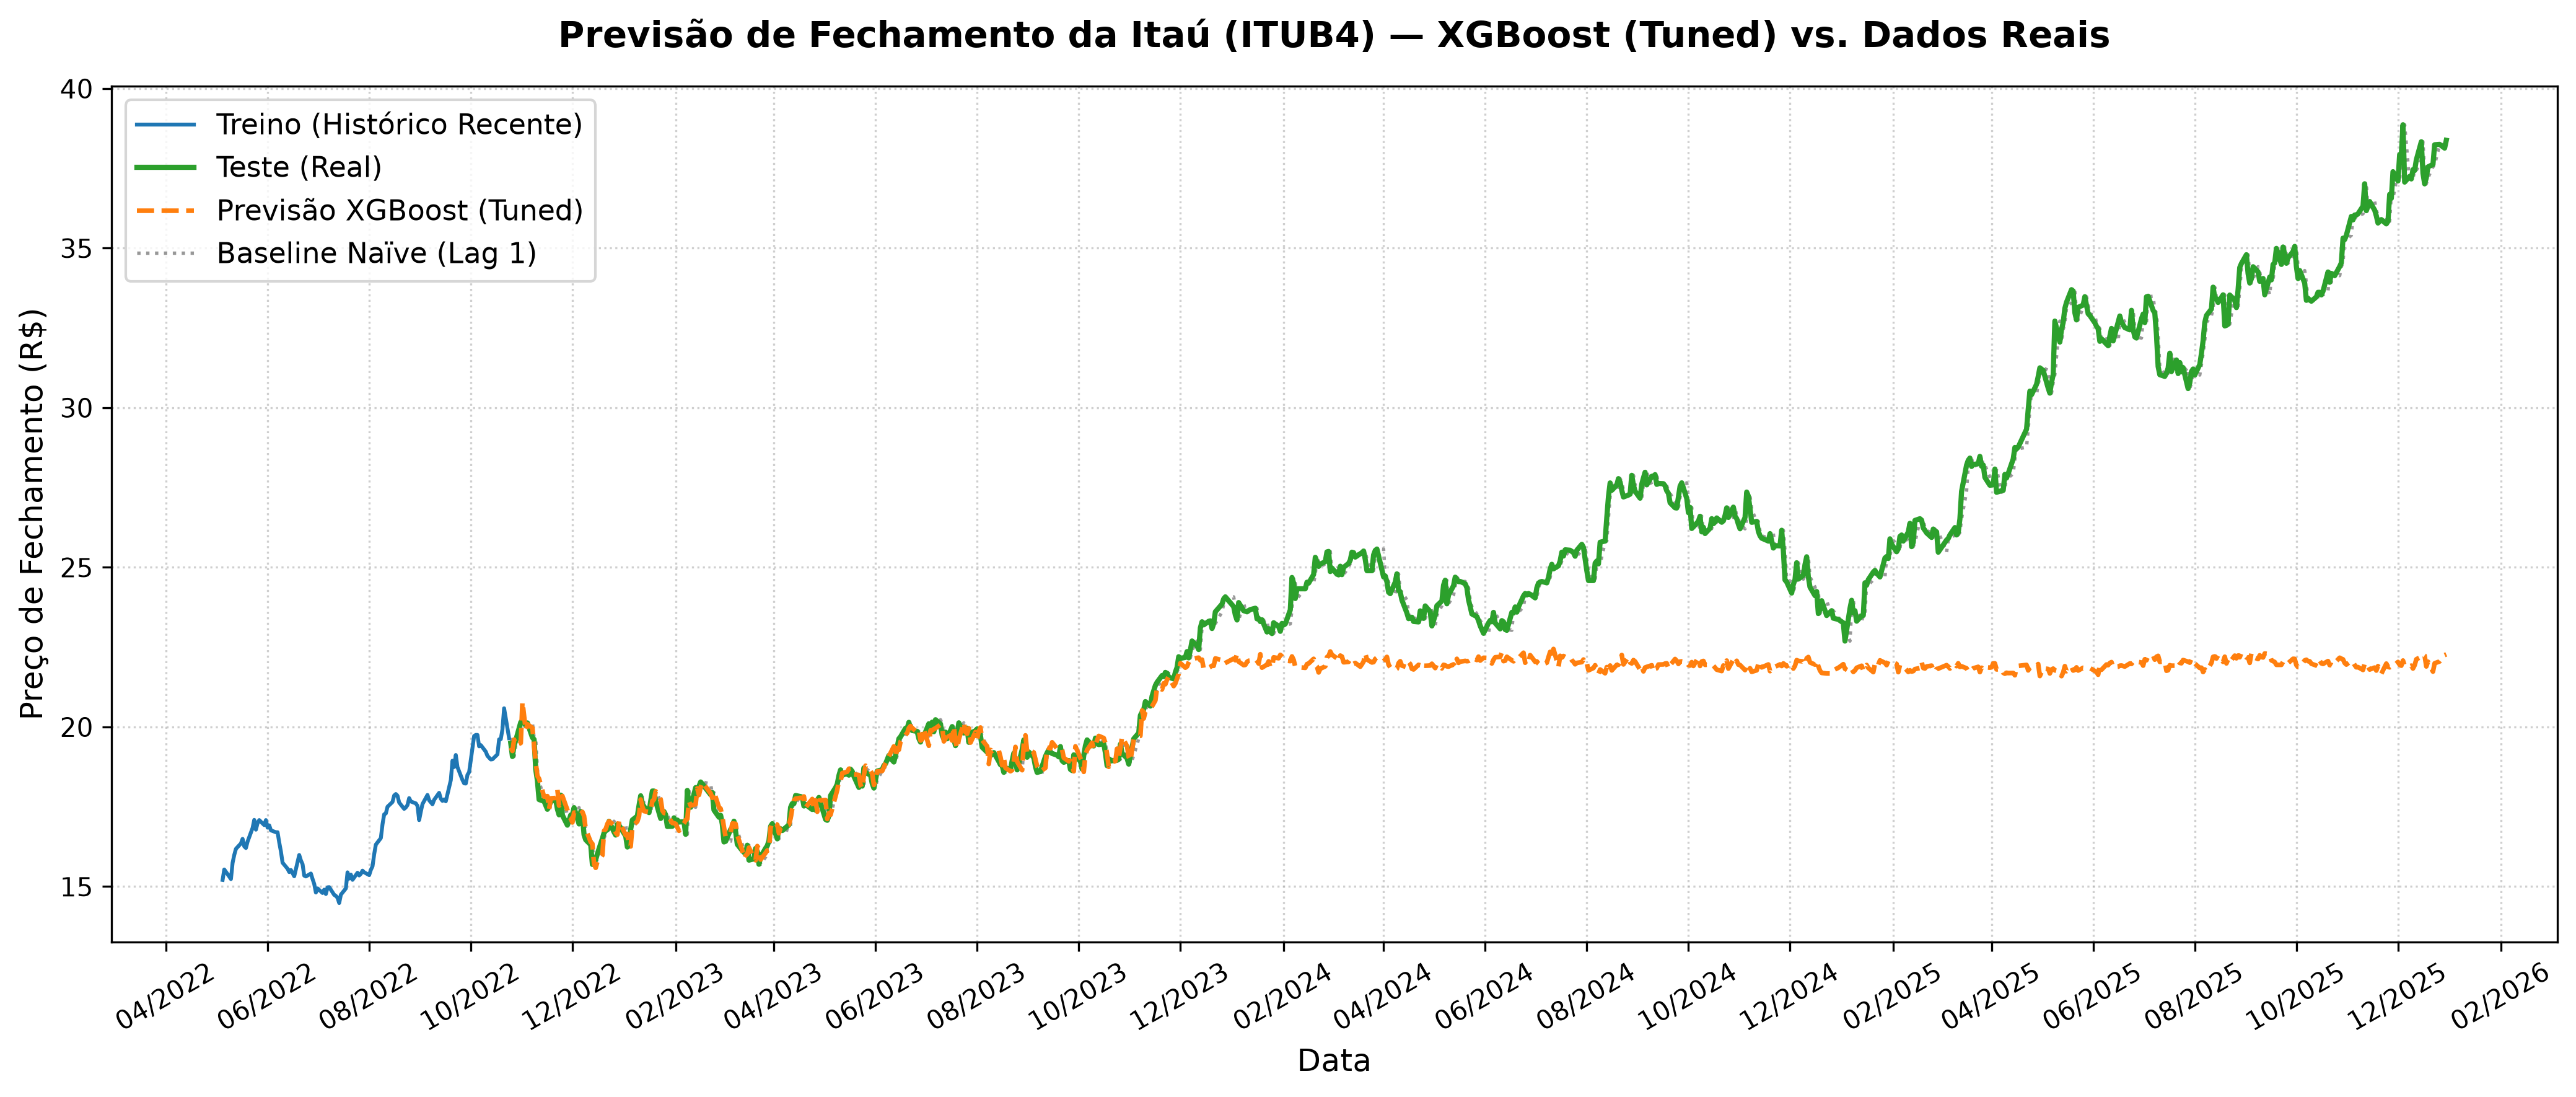

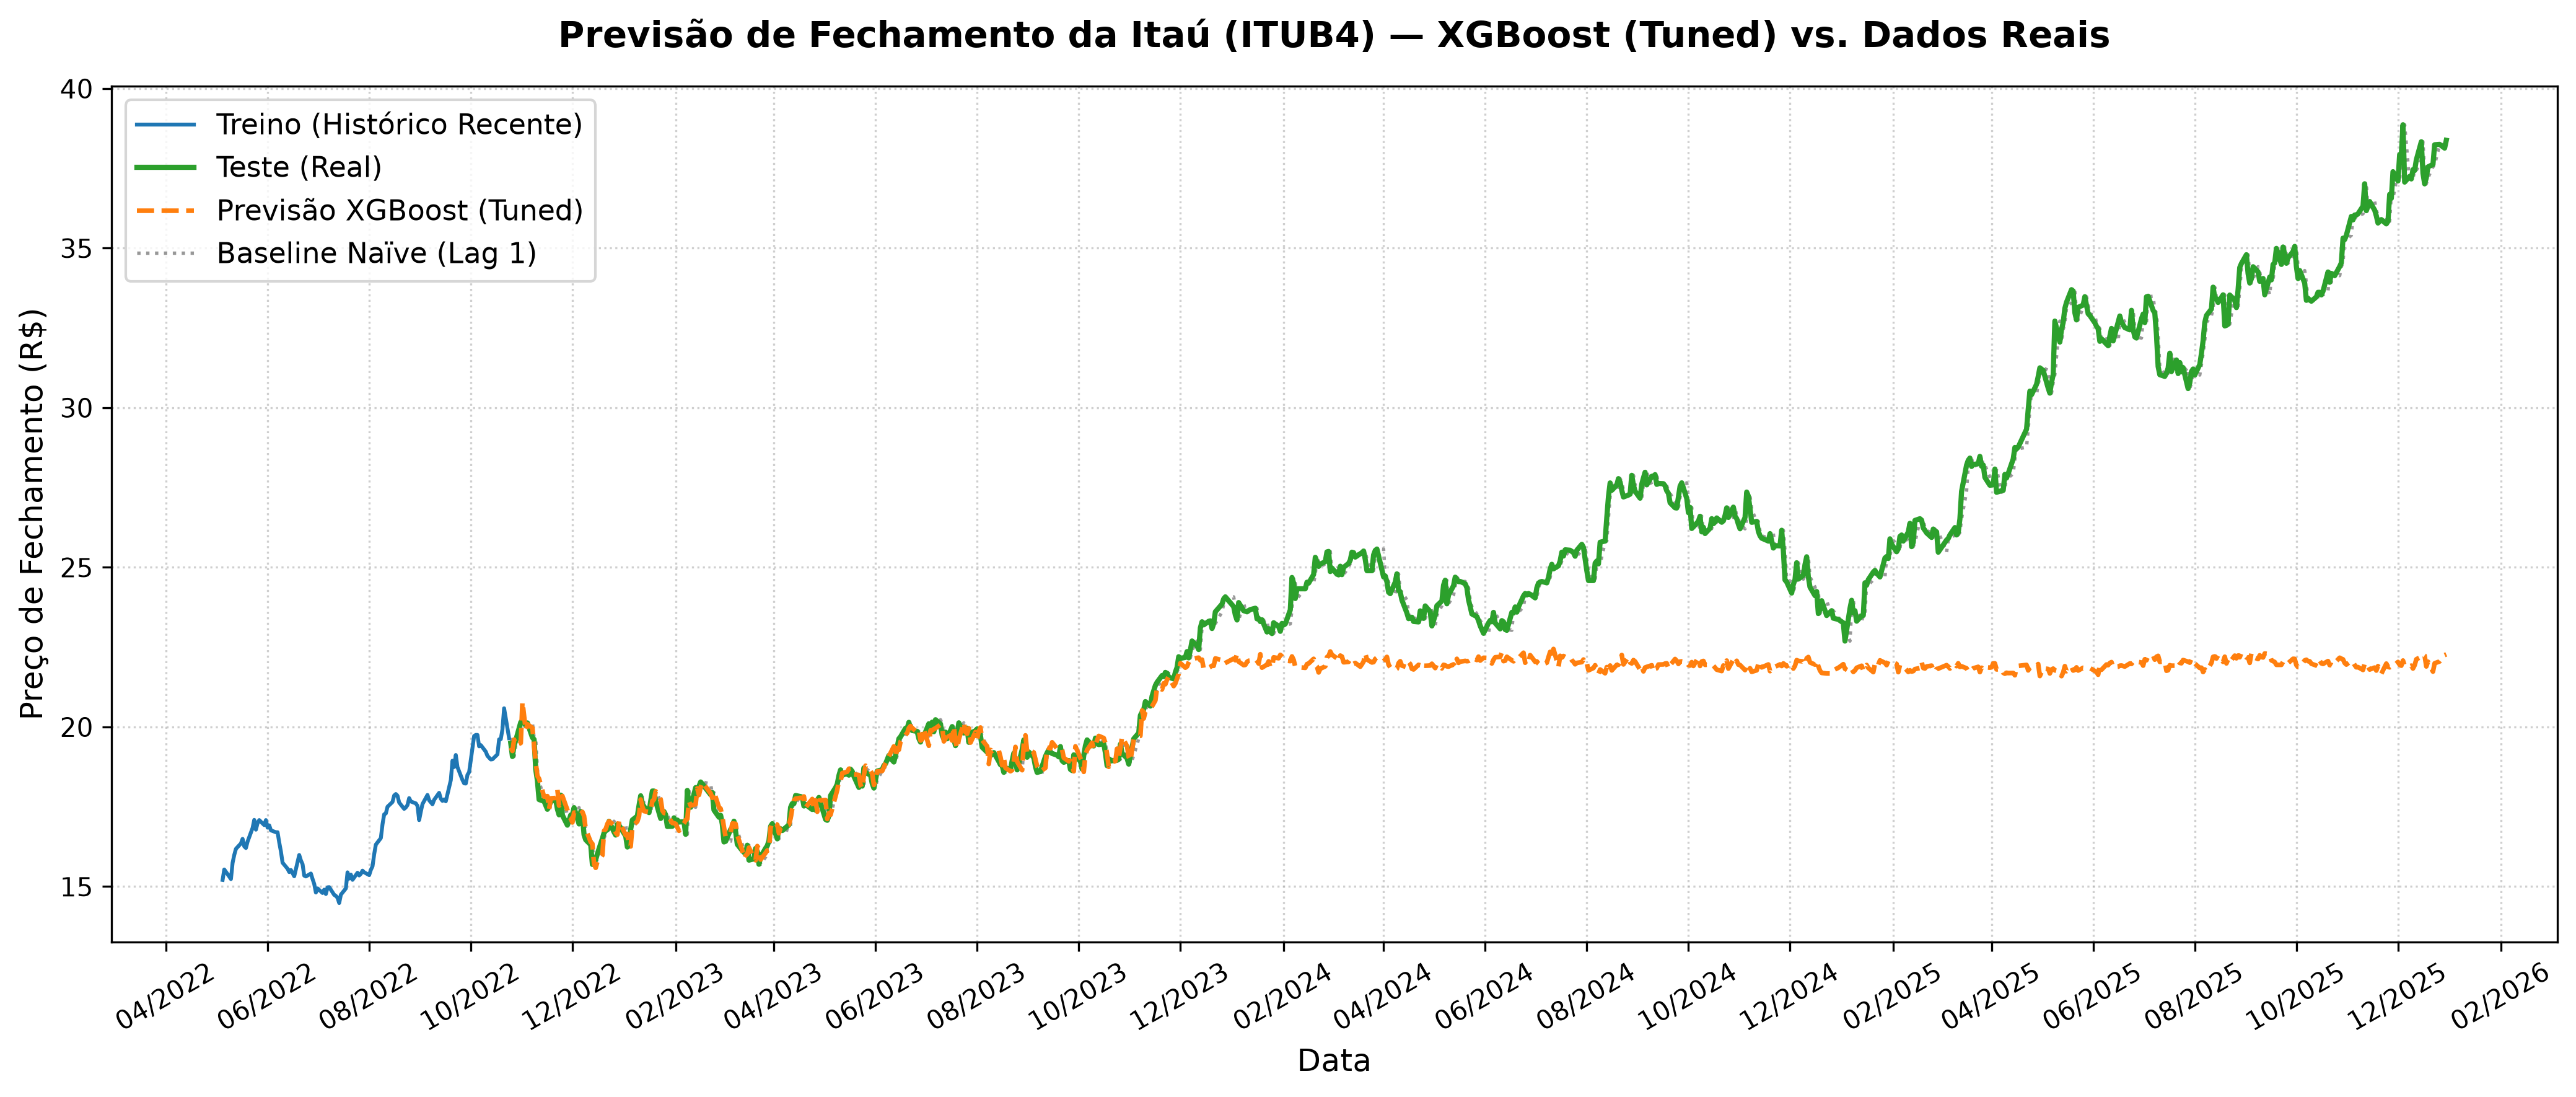

In [6]:
res = run_xgbooster(train_itub, test_itub, "itub")
plot_forecast(
    train_itub, test_itub,
    predictions=res["predictions"],
    stock_name="itub",
    model_name="XGBoost (Tuned)",
    ticker_label="ITUB4",
    company_name="Itaú",
    baseline=res["ontem"],        # baseline naive (preço de ontem)
)

In [ ]:
res_lstm = run_lstm(train_itub, test_itub, "itub", max_epochs=10)
plot_forecast(train_itub, test_itub, res_lstm["predictions"], "itub",
              model_name="LSTM (Tuned)", ticker_label="ITUB4",
              company_name="Itaú", baseline=res_lstm["ontem"])